## ДЗ №1. Метрики и простейшие алгоритмы рекомендаций

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm.auto import tqdm
from typing import List, Optional
from metric_tests import run_tests

%matplotlib inline

## О задании

В этой работе мы посмотрим на то, как работают самые простые модели для рекомендаций. Как правило, они не требуют построения специальных моделей, но даже так оказываются полезны в качестве бейзлайна. Попробуем сделать предсказания с помощью EASE. Это тоже довольно простой подход, но не стоит забывать, что сложные модели могут оказаться не лучшим выбором в условиях большого количества данных. Посчитаем метрики, построим графики и подумаем, насколько хорошо эти модели вообще решают поставленную задачу.

Мы будем работать с датасетом по рекомендации фильмов от Kion MTS, который был дан для соревнования. Сперва нужно его предобработать, эта часть повторяет то, что было на семинаре. 

Датасет необходимо скачать: https://ods.ai/competitions/competition-recsys-21/data

Оттуда нужны файлы `interactions.csv` и `items.csv`

Каждое задание весит **1 балл**, если выполнено полностью и без ошибок, **0 баллов** ставится при наличии хотя бы 1 ошибки. Максимальная оценка - **10 баллов**. Шаблоны функций и классов можно менять по своему усмотрению.

In [2]:
df = pd.read_csv('interactions.csv').iloc[:-1]
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [3]:
df['last_watch_dt'] = (pd.to_datetime(df['last_watch_dt']) - pd.to_datetime(df['last_watch_dt']).min())
df['last_watch_dt'] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
44605,175801,15580,10,6417,98.0
3077807,555746,3349,54,5249,100.0
4596664,976573,142,86,6643,100.0
3246717,861844,6166,31,5324,8.0
4633997,240655,9728,126,6501,95.0


Сделаем разбиение по времени

<Axes: >

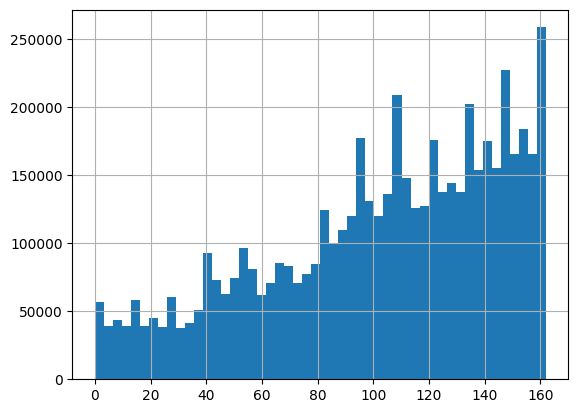

In [4]:
df.last_watch_dt.hist(bins=50)

In [5]:
train_df = df.loc[(df.last_watch_dt < 160-7)].copy()
test_df = df.loc[(df.last_watch_dt >= 160-7)].copy()

train_users = train_df.user_id.unique()
test_users = test_df.user_id.unique()

all_included = np.intersect1d(train_users, test_users)

print('число людей и там и там: ', all_included.shape[0])
print('число людей всего:', train_users.shape[0])

число людей и там и там:  134670
число людей всего: 880449


In [6]:
len(set(test_users) - set(train_users)) / len(test_users)

0.37768022181146027

И переведём всё к соединённому датасету:

In [7]:
n_users = 10000

all_included = np.random.choice(all_included, size=n_users, replace=False)

train_df = train_df.loc[train_df.user_id.isin(all_included)].copy()
test_df = test_df.loc[test_df.user_id.isin(all_included)].copy()

assert train_df.last_watch_dt.max() < test_df.last_watch_dt.min()
assert train_df.user_id.nunique() == n_users
assert test_df.user_id.nunique() == n_users

In [8]:
train_df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
40,127724,5658,147,2447,45.0
71,785328,13165,13,7,1.0
207,170430,12148,66,111,0.0
350,383077,3500,91,7475,100.0
374,744933,11334,134,21782,10.0


In [9]:
train_grouped = train_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                 x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
train_grouped.rename({0:'train_interactions'}, axis=1, inplace=True)

test_grouped = test_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                         x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
test_grouped.rename({0:'test_interactions'}, axis=1, inplace=True)

train_grouped.head()

C:\Temp\ipykernel_15000\1105526701.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_grouped = train_df.groupby('user_id').apply(
C:\Temp\ipykernel_15000\1105526701.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_grouped = test_df.groupby('user_id').apply(


,user_id,train_interactions
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129..."
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1..."
2,75,"[(11237, 20)]"
3,165,"[(12173, 122)]"
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11..."


In [10]:
joined = train_grouped.merge(test_grouped)
joined.head()

,user_id,train_interactions,test_interactions
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]"
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]"
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]"
3,165,"[(12173, 122)]","[(4969, 161)]"
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213..."


In [11]:
np.random.seed(777)

class Random:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        items = set()
        for _, row in df.iterrows():
            for item, _ in row[col]:
                items.add(item)

        self.items = list(items)
        self.trained = True

    def predict(self, df, topn=10):
        assert self.trained
        return [np.random.choice(self.items, replace=False, size=topn)]*len(df)


random = Random()
random.fit(joined)

joined['random_recs'] = random.predict(joined, topn=3)
joined.head()

,user_id,train_interactions,test_interactions,random_recs
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]","[1961, 15991, 3121]"
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]","[1961, 15991, 3121]"
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]","[1961, 15991, 3121]"
3,165,"[(12173, 122)]","[(4969, 161)]","[1961, 15991, 3121]"
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213...","[1961, 15991, 3121]"


**Задание №1. Метрики и бейзлайны**

Добавьте реализацию метрик AP, RR, HR, их усреднённые версии по $U$ мы посчитаем ниже, если следовать коду с семинара, поэтому формулы немного отличаются. За имплементацию с циклами балл будет снижаться, векторизуйте! ( ͡° ͜ʖ ͡°)

$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$
p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)
$$
$$
RR@k = \dfrac{1}{\text{rank}_i@k}
$$
$$
HR@k = [\exists \ y_i = 1 \ \text{among k preds}]
$$


*   $n_u$ - число айтемов, с которыми взаимодействовал юзер $u$
*   $y_i$ - релевантно ли $i$-ое предсказание, $y_i \in \{0,1\}$
* $\text{rank}_i@k$ - позиция первого релеваннтого айтема среди первых $k$ предсказаний
* HR@k - среди первых $k$ предсказаний есть хотя бы одно релевантное

Считайте, что если `topn` не задано, то берётся всегда $n_u$. 

In [12]:
def ap_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)

    r = np.isin(predictions, gt_items).astype('float')[:topn]
    p_k = np.cumsum(r) / np.arange(1, len(r) + 1)
    return (r * p_k).sum() / min(topn, len(gt_items))

def rr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)
    
    r = np.isin(predictions, gt_items).astype('float')[:topn]
    if not r.any():
        return 0
    return 1 / (np.argmax(r) + 1)

def hr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)
    
    r = np.isin(predictions, gt_items).astype('float')[:topn]
    return float(r.any())


Для вашего удобства в файле `metric_tests.py` есть тесты, но хардкодить их, разумеется, не стоит. 

In [13]:
run_tests(ap_metric, rr_metric, hr_metric)

В следующей ячейке код, который считает и усредняет метрики по юзерам. Он взят с семинара, при желании можно его тоже модифицировать, например, векторизовать. 

In [14]:
def evaluate_recommender(df, model_preds, gt_col='test_interactions'):

    metric_values = []

    for idx, row in df.iterrows():
        gt_items = [x[0] for x in row[gt_col]]
        predictions = row[model_preds]

        ap = ap_metric(gt_items, predictions)
        rr = rr_metric(gt_items, predictions)
        hr = hr_metric(gt_items, predictions)

        metric_values.append((ap, rr, hr))

    return {'map': np.mean([x[0] for x in metric_values]),
            'mrr': np.mean([x[1] for x in metric_values]),
            'hr': np.mean([x[2] for x in metric_values])}

Если вы всё сделали правильно, рандомные предсказания должны дать хоть какое-то качество, но не очень большое.

In [15]:
evaluate_recommender(joined, model_preds='random_recs')

{'map': np.float64(2.222222222222222e-05),
 'mrr': np.float64(6.666666666666666e-05),
 'hr': np.float64(0.0002)}

In [16]:
class TopPopular:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        counts = {}
        for _, row in df.iterrows():
            for item, _ in row[col]:
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:

        assert self.trained
        return [self.recommenations[:topn]]*len(df)


toppop = TopPopular()
toppop.fit(joined)

joined['toppopular_recs'] = toppop.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
3,165,"[(12173, 122)]","[(4969, 161)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213...","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."


Самые популярные предсказания должны показать более высокое качество.

In [17]:
evaluate_recommender(joined, model_preds='toppopular_recs')

{'map': np.float64(0.06435063640085664),
 'mrr': np.float64(0.11620936507936508),
 'hr': np.float64(0.2662)}

**Задание №2. Рекомендации в окне**

Здесь необходимо переделать метод рекомендации по популярности так, что популярность считается только за какое-то более свежее временное окно. Под окном подразумевается какой-то временной промежуток, например, ближайший месяц. Соответственно, всё что за его пределами, не учитывается.

In [18]:
train_df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
40,127724,5658,147,2447,45.0
71,785328,13165,13,7,1.0
207,170430,12148,66,111,0.0
350,383077,3500,91,7475,100.0
374,744933,11334,134,21782,10.0


In [19]:
joined

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
3,165,"[(12173, 122)]","[(4969, 161)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213...","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
...,...,...,...,...,...
9995,1096895,"[(16270, 140)]","[(12192, 154), (15034, 162)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
9996,1097036,"[(12995, 89), (9159, 92), (4740, 93), (13865, ...","[(11118, 156), (9435, 159), (3532, 159)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
9997,1097220,"[(7460, 82), (9809, 85), (9900, 85), (11710, 8...","[(10939, 156), (7829, 156), (10464, 156)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
9998,1097296,"[(4740, 69), (3076, 147), (7424, 148), (5190, ...","[(9658, 153), (12360, 154), (5023, 154), (1608...","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."


In [20]:
class TopPopularWeighted(TopPopular):

    def __init__(self, min_window=2):
        super().__init__()
        self.min_window = min_window

    def get_max_dt(self, df, col):
        max_dt = 0
        for _, row in df.iterrows():
            for _, dt in row[col]:
                max_dt = max(max_dt, dt)
        return max_dt

    def fit(self, df, col='train_interactions'):
        counts = {}
        max_dt = self.get_max_dt(df, col)
        for _, row in df.iterrows():
            for item, dt in row[col]:
                if (max_dt - dt) > self.min_window:
                    continue
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1
        
        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:
    
        assert self.trained
        return [self.recommenations[:topn]]*len(df)

toppopweighted = TopPopularWeighted()
toppopweighted.fit(joined)

joined['toppopweighted_recs'] = toppopweighted.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[9728, 10440, 15297, 4151, 341, 7793, 12192, 1..."
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[9728, 10440, 15297, 4151, 341, 7793, 12192, 1..."
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[9728, 10440, 15297, 4151, 341, 7793, 12192, 1..."
3,165,"[(12173, 122)]","[(4969, 161)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[9728, 10440, 15297, 4151, 341, 7793, 12192, 1..."
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213...","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[9728, 10440, 15297, 4151, 341, 7793, 12192, 1..."


Теперь постройте графики зависимости значений трёх метрик (AP@k, RR@k, HR@k) от размера окна. 

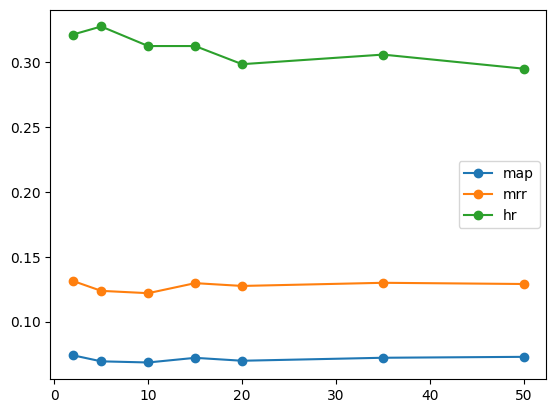

In [21]:
n_window = [2, 5, 10, 15, 20, 35, 50]

map = []
mrr = []
hr = []
for n in n_window:
    toppopweighted = TopPopularWeighted(min_window=n)
    toppopweighted.fit(joined)

    joined['toppopweighted_recs'] = toppopweighted.predict(joined)
    
    temp_metrics = evaluate_recommender(joined, model_preds='toppopweighted_recs')
    map += [temp_metrics['map']]
    mrr += [temp_metrics['mrr']]
    hr += [temp_metrics['hr']]

plt.plot(n_window, map, label='map', marker='o')
plt.plot(n_window, mrr, label='mrr', marker='o')
plt.plot(n_window, hr, label='hr', marker='o')
plt.legend()

Подумайте и ответьте, как размер окна влияет на качество рекомендаций. Какое значение наилучшее, есть ли у этого разумное объяснение?

**Ответ:**

**Задание №3. Метрики и k.**

Постройте зависимость значений MAP@K, MRR@K, HR@K для метода рекомендации по популярности. Возьмите какие-нибудь k, например, от 1 до 100, переберите значения и покажите на линейном графике. 

In [ ]:
joined['toppopular_recs'] = toppop.predict(joined, topn=100)

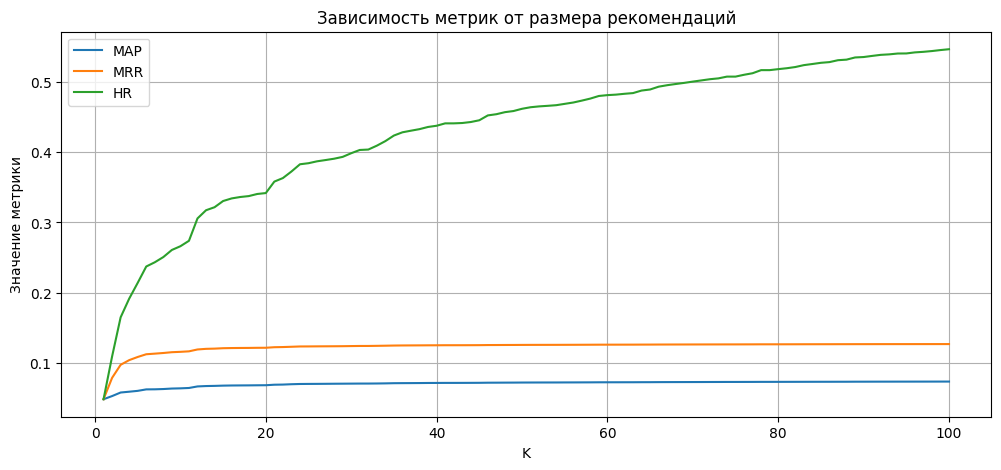

In [30]:
k_values = range(1, 101)

map_values = []
mrr_values = []
hr_values = []

for k in k_values:
    joined['toppopular_recs'] = toppop.predict(joined, topn=k)
    metrics = evaluate_recommender(joined, model_preds='toppopular_recs')

    map_values.append(metrics['map'])
    mrr_values.append(metrics['mrr'])
    hr_values.append(metrics['hr'])

plt.figure(figsize=(12, 5))

plt.plot(k_values, map_values, label='MAP')
plt.plot(k_values, mrr_values, label='MRR')
plt.plot(k_values, hr_values, label='HR')

plt.xlabel('K')
plt.ylabel('Значение метрики')
plt.title('Зависимость метрик от размера рекомендаций')
plt.legend()
plt.grid()
plt.show()

Хорошенько подумайте и ответьте на вопросы ниже.

3.1 Какие из метрик являются монотонными функциями по top-K? Объясните, почему они являются монотонными? \
**Ответ:**

3.2 Объясните по каждой метрике, как можно интерпретировать ее график? То есть, что можно сказать про связь изменения метрики c возможными пользовательскими сценариями, например,скроллингом ленты новостей. \
**Ответ:**

3.3 Как вы думаете, почему графики выглядят именно так? Должны ли они возрастать/убывать, от чего это может зависеть? (Тут вам может помочь дополнительный анализ данных)\
**Ответ:**

**Задание №4. Интерпретация рейтингов**

Возьмите названия фильмов/сериалов из `items.csv`, выделите 5 различных сценариев изменения популярности у фильмов, аргументируйте (например, графиком или статистикой) и проинтерпретируейте их (почему популярность для этого фильма меняется так). Обратите внимание, что надо найти именно разные паттерны изменения вероятностей. 

In [31]:
items = pd.read_csv('items.csv')[['item_id','title']].copy()
items.head()

,item_id,title
0,10711,Поговори с ней
1,2508,Голые перцы
2,10716,Тактическая сила
3,7868,45 лет
4,16268,Все решает мгновение


Пример:

1917


<Axes: >

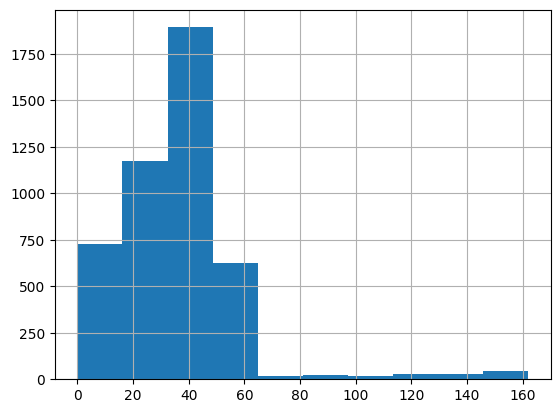

In [32]:
popular_items = df.item_id.value_counts()[:300].index.tolist()
sampled_id = np.random.choice(popular_items)

# это для примера, хотя выцеплять случаи по одному может быть не лучшей идеей
sampled_id = 3402

interactions = df.loc[df.item_id==sampled_id].copy()
name = items.loc[items.item_id==sampled_id].title.values[0]
print(name)
interactions.last_watch_dt.hist()

Фильм 1917 какое-то время набирал популярность, потом видим резкое падение (кстати, с какой даты?). Возможно, это связано с ограничением доступности этого фильма для части пользователей, периодом проката фильма / рекламной кампании или другой причиной. 

Добавьте 5 своих примеров ниже. Опишите, как вы их искали. 

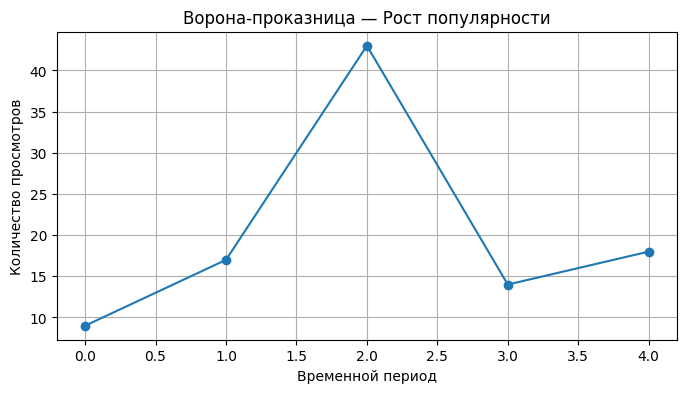

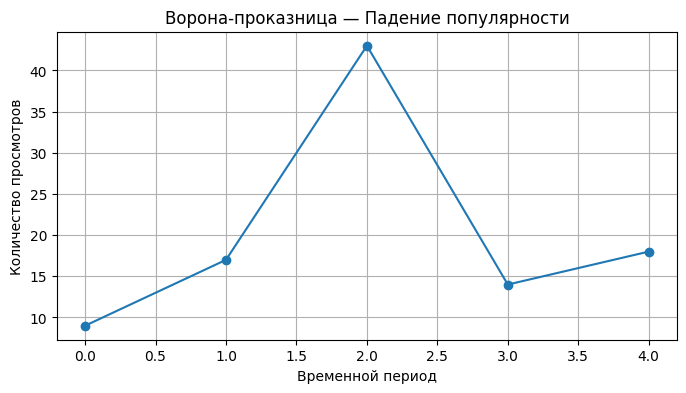

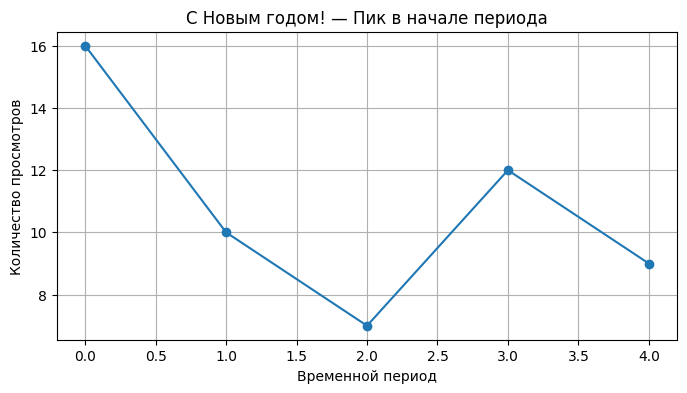

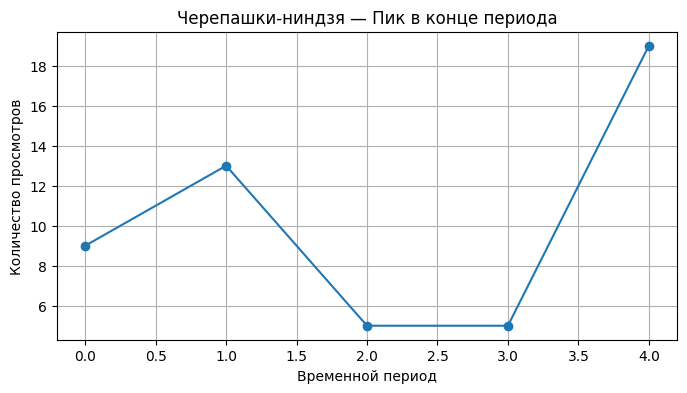

In [37]:
# Разделим временной промежуток на 5 частей
df['time_period'] = pd.cut(
    df['last_watch_dt'],
    bins=5,
    labels=False
)

# Посчитаем количество просмотров каждого фильма в каждом периоде
popularity = df.pivot_table(
    index='item_id',
    columns='time_period',
    values='user_id',
    aggfunc='count',
    fill_value=0
)

# Выберем фильмы с различными сценариями изменения популярности
popularity = popularity[popularity.sum(axis=1) >= 50]
popularity['first'] = popularity.iloc[:, 0]
popularity['last'] = popularity.iloc[:, -1]
popularity['change'] = popularity['last'] - popularity['first']

examples = {
    'Рост популярности': popularity['change'].nlargest(1).index[0],
    'Падение популярности': popularity['change'].nsmallest(1).index[0],
    'Пик в начале периода': popularity.iloc[:, 0:-1].idxmax(axis=1).sort_values().index[0],
    'Пик в конце периода': popularity.iloc[:, 0:-1].idxmax(axis=1).sort_values().index[-1]
}

for description, item_id in examples.items():
    name = items.loc[items.item_id == item_id, 'title'].values[0]

    item_data = popularity.loc[item_id].iloc[:-3]

    plt.figure(figsize=(8, 4))
    plt.plot(range(len(item_data)), item_data.values, marker='o')
    plt.title(name + ' — ' + description)
    plt.xlabel('Временной период')
    plt.ylabel('Количество просмотров')
    plt.grid()
    plt.show()

**Задание №5. User-item encoding**

Теперь, создайте матрицу интеракций user-item по примеру из семинара. Вам нужно в итоге получить разреженную матрицу (sparse matrix), в которой в качестве строк будут пользователи, в качестве колонок - айтемы. Не забудьте перекодировать пользователей и айтемы через энкодер. В отличие от семинара, оставьте в матрице только юзеров и айтемы, которые встречались в матрице > 4 раз.

Важно: когда вы отфильтруете юзеров на встречаемость > 4 раз, вы удалите какие-то айтемы, которые теперь станут встречаться меньше 5 раз. Поэтому у вас перестанет выполняться второе условие на минимальное число интеракций с айтемом. Тогда вам надо опять отфильтровать айтемы на встречаемость, но это снова может нарушить условие для юзеров. В таком случае, вам надо написать итеративный алгоритм до сходимости, пока требования не будут выполняться в обеих колонках. 

In [38]:
def filter_column(df, min_freq):
    """
    Filter dataframe, excluding least active users and least popular items.
    Return a copy of the dataframe with at least min_freq entries
    in both users and items
    """
    counts = df['user_id'].value_counts()
    return df[df['user_id'].isin(counts[counts >= min_freq].index)].copy()

def filter_dataframe(df, cols, min_freq=5):
    """
    Filter dataframe by given columns until each of them satisfies
    min_freq condition, guaranteed by filter_columns. Return a copy
    of the dataframe
    """
    filtered = df.copy()

    while True:
        old_size = len(filtered)

        for col in cols:
            counts = filtered[col].value_counts()
            filtered = filtered[
                filtered[col].isin(counts[counts >= min_freq].index)
            ]

        if len(filtered) == old_size:
            break

    return filtered

filtered_train = filter_dataframe(
    train_df,
    ['user_id', 'item_id'],
    min_freq=5
)

In [41]:
def df_encode(df):
    global item2id, user2id, id2item, id2user
    item2id = {k:v for v, k in enumerate(df.item_id.unique())}
    user2id = {k:v for v, k in enumerate(df.user_id.unique())}

    id2item = {k:v for v, k in item2id.items()}
    id2user = {k:v for v, k in user2id.items()}

    df['user_id'] = df.user_id.apply(lambda x: user2id[x])
    df['item_id'] = df.item_id.apply(lambda x: item2id[x])
    return df

filtered_train = df_encode(filtered_train)
filtered_train.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
2611905,216,454,80,8150,100.0
1276817,2794,1221,138,4330,82.0
2629358,758,200,88,6207,92.0
3014588,2542,854,147,24034,100.0
3710740,3399,2245,136,3060,45.0


In [42]:
from scipy import sparse as sps

matrix = sps.coo_matrix(
    (
        np.ones(filtered_train.shape[0]),
        (filtered_train['user_id'], filtered_train['item_id'])
    ),
    shape=(len(user2id), len(item2id))
)

matrix

<COOrdinate sparse matrix of dtype 'float64'
	with 106029 stored elements and shape (5890, 3024)>

**Задание №6. Интеракции и частота**

Постройте график зависимости количества айтемов и юзеров от значений (порогов) фильтров на встречаемость в матрице интеракций. То есть, нужно выполнить задание №5 для нескольких значений `min_freq` и построить график зависимости числа оставшихся айтемов и юзеров от этого параметра. 

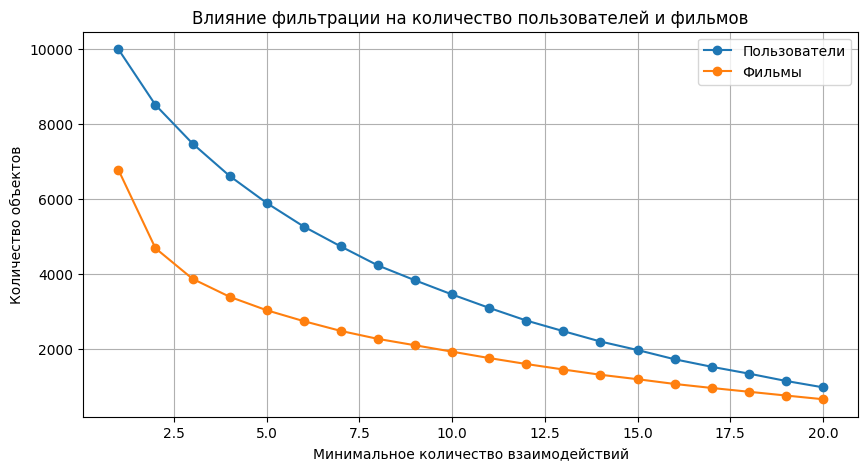

In [43]:
freq_values = range(1, 21)

users_count = []
items_count = []

for freq in freq_values:
    filtered = filter_dataframe(
        train_df,
        ['user_id', 'item_id'],
        min_freq=freq
    )

    users_count.append(filtered.user_id.nunique())
    items_count.append(filtered.item_id.nunique())

plt.figure(figsize=(10, 5))

plt.plot(freq_values, users_count, marker='o', label='Пользователи')
plt.plot(freq_values, items_count, marker='o', label='Фильмы')

plt.xlabel('Минимальное количество взаимодействий')
plt.ylabel('Количество объектов')
plt.title('Влияние фильтрации на количество пользователей и фильмов')
plt.legend()
plt.grid()
plt.show()

**Задание №7. EASE**

Реализуйте EASE, постройте рекомендации для юзеров. Сравните все имплементированные ранее метрики качества с `TopPopular` для некоторого набора k. 

Реализацию можно взять из семинара. Можно реализовать по статье https://arxiv.org/pdf/1905.03375.pdf. Можно взять и адаптировать из RecBole https://github.com/RUCAIBox/RecBole.

In [44]:
%%time

# Обучаем конечную модель
# Мы взяли реализацию из RecBole
#
def fit_ease(X, reg_weight=1000):

    X = X.toarray()
    
    G = X.T @ X
    G += reg_weight * np.eye(G.shape[0])

    P = np.linalg.inv(G)
    B = -P / np.diag(P)
    np.fill_diagonal(B, 0)

    return B

w = fit_ease(matrix)

CPU times: total: 9.56 s
Wall time: 1.23 s


Далее, вам надо реализовать функцию получения предсказаний. У вас есть обученная матрица весов, которую можно использовать для получения предсказаний. Для этого нужно построить вектор интеракций пользователя и умножить его на матрицу весов.

In [46]:
def get_preds(x, item2id, id2item):

    user_items = [
        item2id[item]
        for item, date in x
        if item in item2id
    ]
    
    scores = np.zeros(w.shape[0])

    scores[user_items] = 1

    scores = scores @ w

    scores[user_items] = -np.inf

    top_items = np.argsort(scores)[::-1][:100]

    decoded = [id2item[item] for item in top_items]

    return decoded


joined['ease_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item))
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs,ease_preds
0,47,"[(13361, 138), (13865, 138), (7401, 142), (129...","[(14488, 160)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2..."
1,55,"[(9896, 15), (6192, 60), (3076, 99), (15297, 1...","[(14, 156)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2..."
2,75,"[(11237, 20)]","[(4151, 158), (15297, 158)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2..."
3,165,"[(12173, 122)]","[(4969, 161)]","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 2..."
4,241,"[(5051, 9), (2134, 9), (13913, 112), (6646, 11...","[(6162, 156), (10440, 156), (8986, 156), (1213...","[1961, 15991, 3121]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[68, 526, 129, 71, 93, 1480, 44, 337, 126, 263..."


In [47]:
topn_values = [5, 10, 20, 50, 100]

results = []

for k in topn_values:
    ease_metrics = evaluate_recommender(
        joined.assign(ease_preds=joined.ease_preds.apply(lambda x: x[:k])),
        'ease_preds'
    )

    popular_metrics = evaluate_recommender(
        joined.assign(toppopular_recs=joined.toppopular_recs.apply(lambda x: x[:k])),
        'toppopular_recs'
    )
    
    results.append({
        'K': k,
        'EASE MAP': ease_metrics['map'],
        'EASE MRR': ease_metrics['mrr'],
        'EASE HR': ease_metrics['hr'],
        'Popular MAP': popular_metrics['map'],
        'Popular MRR': popular_metrics['mrr'],
        'Popular HR': popular_metrics['hr']
    })

results = pd.DataFrame(results)
results

,K,EASE MAP,EASE MRR,EASE HR,Popular MAP,Popular MRR,Popular HR
0,5,0.000037,0.000105,0.0005,0.060783,0.108908,0.2142
1,10,0.000055,0.000199,0.0013,0.064351,0.116209,0.2662
2,20,0.000062,0.000257,0.0022,0.068784,0.121989,0.3417
3,50,0.000115,0.000421,0.0075,0.072592,0.126034,0.4614
4,100,0.000143,0.000509,0.0142,0.073975,0.127224,0.5460


Сделайте выводы — какой алгоритм работает лучше?

**Ответ:**

**Задание №8. Тюнинг**

Переберите различные значения гиперпараметра коэффициента регуляризации у EASE и постройте графики, как в задании №6. Постарайтесь "затюнить" EASE как можно лучше. Возьмите разумное число гиперпараметров - хотя бы штук 20 по логарифмической сетке, либо используйте более хитрые алгоритмы оптимизации. 

  0%|          | 0/20 [00:00<?, ?it/s]

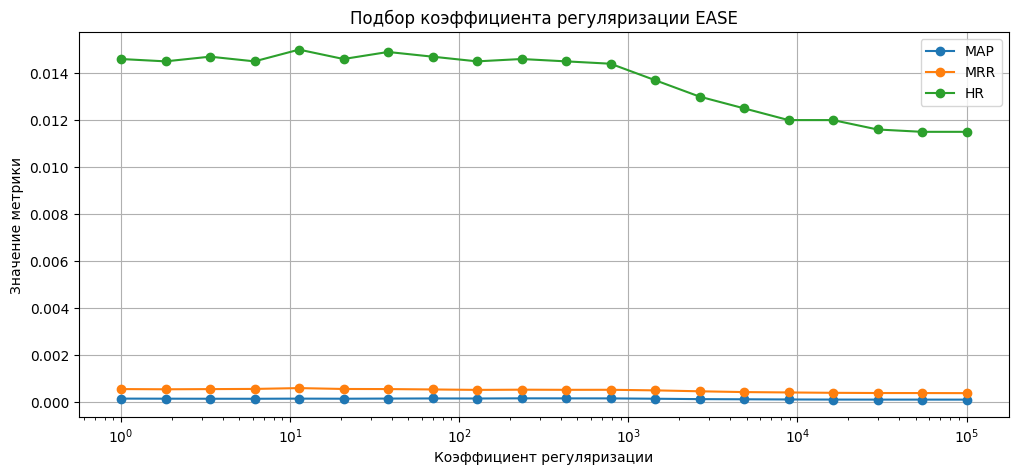

,reg,map,mrr,hr
0,1.000000,0.000142,0.000548,0.0146
1,1.832981,0.000138,0.000539,0.0145
2,3.359818,0.000136,0.000546,0.0147
3,6.158482,0.000135,0.000554,0.0145
4,11.288379,0.000141,0.000589,0.0150
5,20.691381,0.000137,0.000552,0.0146
6,37.926902,0.000143,0.000548,0.0149
7,69.519280,0.000148,0.000531,0.0147
8,127.427499,0.000146,0.000513,0.0145
9,233.572147,0.000153,0.000522,0.0146


In [48]:
reg_values = np.logspace(0, 5, 20)

tuning_results = []

for reg in tqdm(reg_values):
    weights = fit_ease(matrix, reg_weight=reg)

    w = weights

    joined['ease_tuning'] = joined.train_interactions.apply(
        lambda x: get_preds(x, item2id, id2item)
    )

    metrics = evaluate_recommender(joined, 'ease_tuning')

    tuning_results.append({
        'reg': reg,
        'map': metrics['map'],
        'mrr': metrics['mrr'],
        'hr': metrics['hr']
    })

tuning_results = pd.DataFrame(tuning_results)

plt.figure(figsize=(12, 5))

for metric in ['map', 'mrr', 'hr']:
    plt.plot(
        tuning_results['reg'],
        tuning_results[metric],
        marker='o',
        label=metric.upper()
    )

plt.xscale('log')
plt.xlabel('Коэффициент регуляризации')
plt.ylabel('Значение метрики')
plt.title('Подбор коэффициента регуляризации EASE')
plt.legend()
plt.grid()
plt.show()

tuning_results

Ответьте на следующие вопросы:

8.1 Какое значение гиперпараметра является наилучшим? 


**Ответ:**

8.2 Что еще интересного вы можете сказать по графикам? Может быть, что-то свзяанное с распределением параметров, влиянием на отдельные метрики, скоростью тюнинга?

**Ответ:**

**Задание №9. EASE и topk**

В лекции №2 говорилось, что качество у EASE растет с ослаблением фильтра на число айтемов. В этом задании постройте кривые метрик качества MAP/MRR/HR в зависимости от topk (например, от 1 до 100 с некоторым шагом), где кривая параметризована минимальным требуемым значением встречаемости user/item (из задания №6). Опишите свои выводы.

Важно: в этом задании линии могут быть мало различимыми, поэтому ваша задача для каждой метрики найти нужный масштаб на каких-то конкретных topk, чтобы линии стали визуально отличимы. 

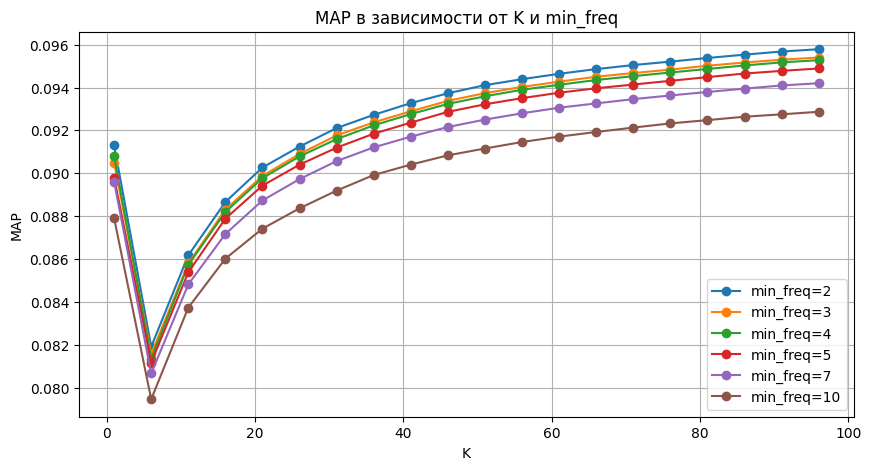

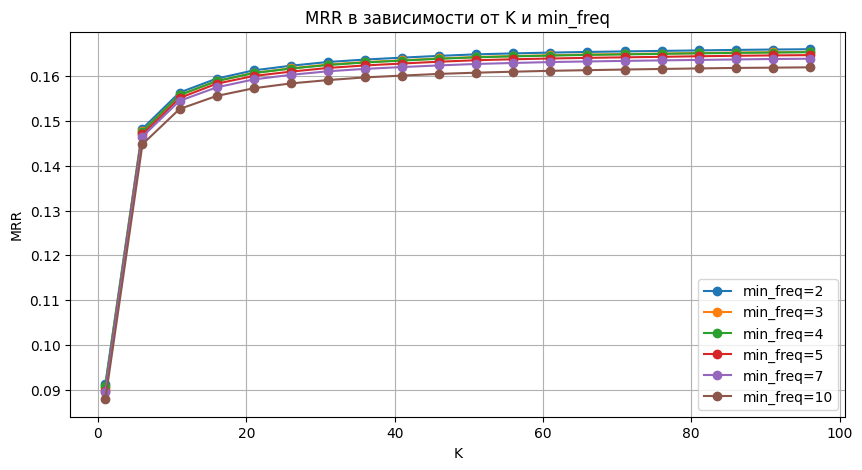

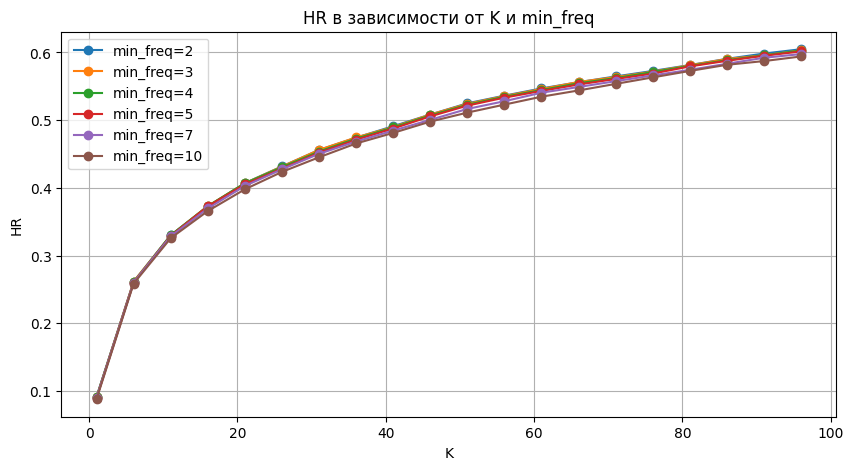

In [49]:
freq_values = [2, 3, 4, 5, 7, 10]
k_values = range(1, 101, 5)

results_by_freq = {}

for freq in freq_values:

    filtered = filter_dataframe(
        train_df,
        ['user_id', 'item_id'],
        min_freq=freq
    )

    encoded = filtered.copy()

    local_item2id = {
        item: i for i, item in enumerate(encoded.item_id.unique())
    }

    local_user2id = {
        user: i for i, user in enumerate(encoded.user_id.unique())
    }

    local_id2item = {
        i: item for item, i in local_item2id.items()
    }

    encoded['item_id'] = encoded['item_id'].map(local_item2id)
    encoded['user_id'] = encoded['user_id'].map(local_user2id)

    X = sps.coo_matrix(
        (
            np.ones(len(encoded)),
            (encoded.user_id, encoded.item_id)
        ),
        shape=(len(local_user2id), len(local_item2id))
    )

    weights = fit_ease(X, reg_weight=1000)

    predictions = []

    for interactions in joined.train_interactions:
        user_items = [
            local_item2id[item]
            for item, date in interactions
            if item in local_item2id
        ]

        scores = np.zeros(weights.shape[0])
        scores[user_items] = 1
        scores = scores @ weights
        scores[user_items] = -np.inf

        top_items = np.argsort(scores)[::-1][:100]

        predictions.append([
            local_id2item[item]
            for item in top_items
        ])

    freq_metrics = []

    for k in k_values:
        values = []

        for i, row in joined.iterrows():
            gt_items = [x[0] for x in row.test_interactions]

            values.append((
                ap_metric(gt_items, predictions[i], topn=k),
                rr_metric(gt_items, predictions[i], topn=k),
                hr_metric(gt_items, predictions[i], topn=k)
            ))

        freq_metrics.append([
            np.mean([x[0] for x in values]),
            np.mean([x[1] for x in values]),
            np.mean([x[2] for x in values])
        ])

    results_by_freq[freq] = pd.DataFrame(
        freq_metrics,
        index=k_values,
        columns=['MAP', 'MRR', 'HR']
    )


for metric in ['MAP', 'MRR', 'HR']:
    plt.figure(figsize=(10, 5))

    for freq in freq_values:
        plt.plot(
            k_values,
            results_by_freq[freq][metric],
            marker='o',
            label=f'min_freq={freq}'
        )

    plt.xlabel('K')
    plt.ylabel(metric)
    plt.title(f'{metric} в зависимости от K и min_freq')
    plt.legend()
    plt.grid()
    plt.show()

Что вы можете сказать на основе полученных графиков? Соответствуют ли они вашим ожиданиям?

**Ответ:**

**Задание №10. Интерпретируемые рекомендации**

Используйте выученную матрицу весов для item2item рекомендаций. Приведите 10 примеров топ-5 рекомендаций от EASE к сэмплируемым айтемам. Используйте названия фильмов вместо id при выводе рекомендаций. 

In [ ]:
# Выберем 10 популярных фильмов
sampled_items = train_df.item_id.value_counts().index.tolist()
sampled_items = [x for x in sampled_items if x in item2id][:10]

# Найдём лучшие рекомендации для каждого фильма
for item in sampled_items:

    item_idx = item2id[item]

    scores = w[item_idx].copy()
    scores[item_idx] = -np.inf

    top_items = np.argsort(scores)[::-1][:5]

    recommended_ids = [id2item[i] for i in top_items]

    item_name = items.loc[
        items.item_id == item, 'title'
    ].values[0]

    recommended_names = items.loc[
        items.item_id.isin(recommended_ids), 'title'
    ].tolist()

    print('Исходный фильм:', item_name)
    print('Рекомендации:')

    for name in recommended_names:
        print('-', name)

    print()

Исходный фильм: Подслушано
Рекомендации:
- Призрак
- Четыре возраста любви
- Марафонец
- Пинкфонг. Песни про космос
- Эвротико 7

Исходный фильм: Маша
Рекомендации:
- Четыре возраста любви
- Второй шанс Кэрол
- Партия для чемпионки
- Без срока давности. Эшелоны смерти
- Медвежонок Винни и его друзья

Исходный фильм: Аферистка
Рекомендации:
- Позитивное утро
- Четыре возраста любви
- Без срока давности. Эшелоны смерти
- Три дня Виктора Чернышева
- Медвежонок Винни и его друзья

Исходный фильм: Секс и ничего лишнего
Рекомендации:
- Конец сезона
- Куда ты пропала, Бернадетт
- Старшая жена
- Влюблен по собственному желанию

Исходный фильм: Крёстная мама
Рекомендации:
- Четыре возраста любви
- Кавасаки Фронтель - Бэйцзин Гоань
- Девушка в чулках с подвязками
- Второй шанс Кэрол
- Без срока давности. Эшелоны смерти

Исходный фильм: Чкалов
Рекомендации:
- Замок с привидениями
- Второй шанс Кэрол
- Напрасная жертва
- Смертельный круиз
- В плену обмана

Исходный фильм: Чёрная пантера
Рекомендац

Хорошие ли получились рекомендации? Почему? Есть ли хорошие примеры? Есть ли плохие? Почему бывают плохие примеры?

**Ответ:**